# INT/COHE/UNW demo

In [ ]:
"""
File Name: int_cohe_unw_demo.ipynb

Author:
    F. Minati, F. Vecchioli, A. Morea
    B-Open Solutions srl

Date: August 2025

Description:
------------
This notebook evaluate the performances of CSLC products generated with model-based approach (orbit, ETAD and DEM)
over a set of CRs in Surat basin (Australia), generated from Sentinel-1 data.

"""


Dependencies
-------------
- ortools minimum cost flow library (https://developers.google.com/optimization/flow/mincostflow?hl=it)

Input Data 
----------
- Co-registered Single Look Complex (CSLC) data




In [1]:
# import modules
import xarray as xr
import numpy as np
from rosel import mcf

### Open a single coregistered burst file

In [2]:
crg_data_path = "s3://bopen-sar/ARD-ROSE-L/SENTINEL/Greenland/112/SENTINEL1_112_20230710_20230722_HH/bursts/iw2_239129/coreg/"
crg = xr.open_datatree(crg_data_path, engine="zarr", chunks={}, decode_coords="all")

/tmp/ipykernel_79777/2055980949.py:2: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  crg = xr.open_datatree(crg_data_path, engine='zarr', chunks={}, decode_coords='all')


# Phase estimation

In [3]:
az_looks = 8
rg_looks = 32

In [ ]:
interf = (
    crg["cstack"].isel(acquisition_date=1).squeeze()
    * crg["cstack"].isel(acquisition_date=0).squeeze().conj()
)
interf_ml = (
    interf.coarsen(azimuth_time=az_looks, slant_range_time=rg_looks, boundary="trim")
    .mean()
    .persist()
)
phase_ml = xr.apply_ufunc(np.angle, interf_ml, dask="parallelized").persist()
phase_ml

/home/fminati/anaconda3/envs/unwrap/lib/python3.11/site-packages/dask/array/utils.py:105: ComplexWarning: Casting complex values to real discards the imaginary part
  meta = meta.astype(dtype)


<xarray.DataArray 'cstack' (azimuth_time: 202, slant_range_time: 814)> Size: 658kB
dask.array<transpose, shape=(202, 814), dtype=float32, chunksize=(64, 16), chunktype=numpy.ndarray>
Coordinates:
    azimuth_m         (azimuth_time) float64 2kB dask.array<chunksize=(64,), meta=np.ndarray>
  * azimuth_time      (azimuth_time) datetime64[ns] 2kB 2023-07-10T09:13:52.9...
    slant_range_m     (slant_range_time) float64 7kB dask.array<chunksize=(16,), meta=np.ndarray>
  * slant_range_time  (slant_range_time) float64 7kB 0.005659 ... 0.006063

/home/fminati/anaconda3/envs/unwrap/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))


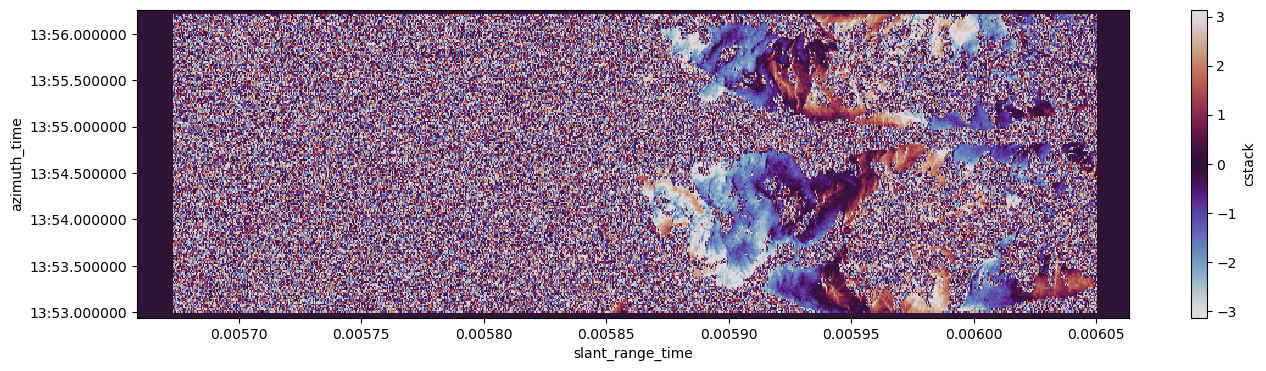

In [6]:
phase_ml.plot(
    vmin=-np.pi, vmax=np.pi, cmap="twilight", add_colorbar=True, figsize=(16, 4)
)

# Coherence estimation

In [7]:
i0 = (
    (np.abs(crg["cstack"].isel(acquisition_date=0).squeeze()) ** 2)
    .coarsen(azimuth_time=az_looks, slant_range_time=rg_looks, boundary="trim")
    .mean()
    .persist()
)
i1 = (
    (np.abs(crg["cstack"].isel(acquisition_date=1).squeeze()) ** 2)
    .coarsen(azimuth_time=az_looks, slant_range_time=rg_looks, boundary="trim")
    .mean()
    .persist()
)

In [8]:
cohe = (np.abs(interf_ml) / np.sqrt(i0 * i1)).persist()

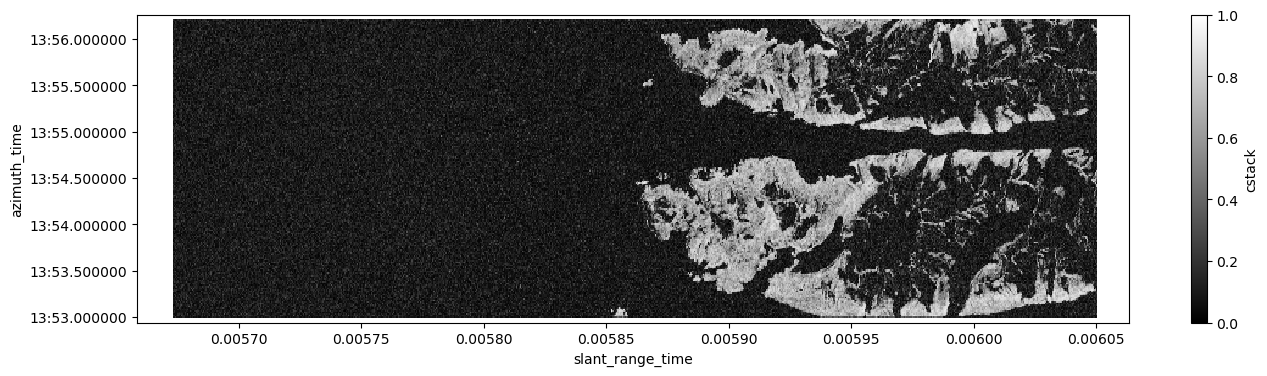

In [9]:
cohe.plot(vmin=0, vmax=1, cmap="gray", add_colorbar=True, figsize=(16, 4))

In [10]:
cohe.drop_vars(["slant_range_m", "azimuth_m"]).to_zarr(
    "/scratch/coherence", mode="w", compute=True, consolidated=True
)
phase_ml.drop_vars(["slant_range_m", "azimuth_m"]).chunk(64).to_zarr(
    "/scratch/phase", mode="w", compute=True, consolidated=True
)

In [11]:
cohe

<xarray.DataArray 'cstack' (azimuth_time: 202, slant_range_time: 814)> Size: 658kB
dask.array<truediv, shape=(202, 814), dtype=float32, chunksize=(64, 16), chunktype=numpy.ndarray>
Coordinates:
    azimuth_m         (azimuth_time) float64 2kB dask.array<chunksize=(64,), meta=np.ndarray>
  * azimuth_time      (azimuth_time) datetime64[ns] 2kB 2023-07-10T09:13:52.9...
    slant_range_m     (slant_range_time) float64 7kB dask.array<chunksize=(16,), meta=np.ndarray>
  * slant_range_time  (slant_range_time) float64 7kB 0.005659 ... 0.006063

# Coherent point selection

In [12]:
yy, xx = np.where(cohe > 0.4)

cc = cohe.values[yy, xx]
pp = phase_ml.values[yy, xx]

# Phase Unwrapping (MCF)

In [13]:
exit_status, flow, sol = mcf.integ_mcf(xx, yy, pp, cc, dict())

2025-08-29 15:41:47 [info     ] Function get_dual_graph Took 0.0252 seconds
2025-08-29 15:41:47 [info     ] Function integ_mcf_ortools Took 0.0210 seconds
2025-08-29 15:41:48 [info     ] Function integ_tree Took 0.7651 seconds
2025-08-29 15:41:48 [info     ] Function solve Took 1.3007 seconds


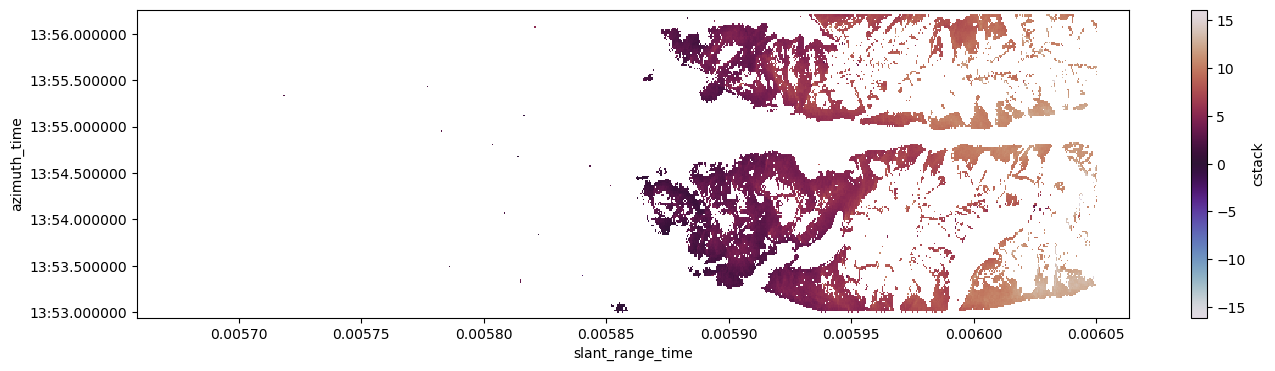

In [14]:
ph_unw = phase_ml.copy()
data = phase_ml.values * np.nan
data[yy, xx] = sol
ph_unw[:, :] = data
ph_unw.plot(cmap="twilight", add_colorbar=True, figsize=(16, 4))